### **INFORME TÉCNICO: CLASIFICACIÓN DE PAISAJES MEDIANTE REDES NEURONALES CONVOLUCIONALES (CNN)**

**Integrantes:** Christian Pastran, Alessandro Rosell, Diego Mancilla

**Seccion**: 001D

### **INTRODUCCION**

1. **Definicion para el Problema del Negocio, Objetivos a buscar y Metricas esperadas en nuestro contexto**:

**1.1** **Introduccion al problema del negocio**: En la actualidad, las plataformas digitales de turismo, agencias de viajes y bancos de imágenes gestionan millones de archivos fotográficos que requieren ser catalogados de forma precisa. La clasificación manual de estos recursos visuales resulta ineficiente, costosa y propensa a errores humanos. **¿Porque es necesario resolver esto?** Porque ayudaria mucho a problemas criticos de eficiencia, costos y organizacion de contenido debido a las cantidad lugares turisticos que podria estar manejando esta misma empresa.

**1.2** Nuestro proyecto busca abordar esta problemática mediante el desarrollo de un modelo de Visión por Computadora basado en Redes Neuronales Convolucionales (CNN). El sistema automatiza el etiquetado y categorización de imágenes extrayendo caracteristicas cruciales utilizando estas capas convolucionales pare despues pasarlo a un modelo **MLP** que utilice la informacion extraida de paisajes, ciudades, playas, etc. Optimizando el motor de búsqueda y recomendación para la busqueda de informacion, minimizando los errores de etiquetado en la plataforma.



**1.3 Objetivos Específicos**

Configurar una variante propia y acotada del dataset para garantizar la reproducibilidad y el balance de clases.

Diseñar e implementar una arquitectura de CNN que extraiga patrones visuales clave (bordes, texturas, colores) de los diferentes paisajes.

Evaluar el rendimiento del modelo mediante métricas de clasificación estándar ($Accuracy$, $Precision$, $Recall$, $F1\text{-Score}$ y Matriz de Confusión).

**1.4 Definición de KPIs y Metas Deseadas**

Para considerar el modelo apto para su despliegue en un entorno de producción (catálogo digital/app de turismo), se establecen los siguientes indicadores clave de rendimiento (KPIs):

-------------------------------------

**Recall Promedio**: >= 85%

  En un catálogo fotográfico o app de turismo, el costo de perder o traspapelar una foto (Falso Negativo) es alto. Queremos asegurar que el modelo identifique correctamente al menos el $85\%$ del total de imágenes reales de cada categoría de paisaje.

**Precision Global**: >= 80%

Mantiene un nivel de exactitud aceptable para evitar que se mezclen demasiadas fotos irrelevantes en las galerías mostradas a los usuarios.

**F1-Score Ponderado**: >= 0.82

Valida el equilibrio global entre el Recall alcanzado y la precisión en todas las clases.



**EXTRACCION DE ARCHIVOS**

En esta parte del trabajo creamos las carpetas necesarias para la extraccion de los archivos del dataset **raw** para el dataset completo sin ningun tipo de cambios en los archivos **processed** para los archivos ya procesados y adaptados a las necesidades del trabajo

In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.models import Model
from tensorflow.keras import Sequential, Input
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix)

import os
import shutil
import zipfile
from pathlib import Path

# Resolver la raíz tanto si el notebook se ejecuta desde el proyecto como desde models/
project_root = Path.cwd()
if not (project_root / "data" / "raw").is_dir() and (project_root.parent / "data" / "raw").is_dir():
    project_root = project_root.parent

# Crear únicamente las carpetas que todavía no existen
directories = ["data/raw", "data/processed", "models", "images"]
for directory in directories:
    directory_path = project_root / directory
    if directory_path.exists():
        print(f"La carpeta ya existe: {directory_path}")
    else:
        directory_path.mkdir(parents=True, exist_ok=True)
        print(f"Carpeta creada: {directory_path}")

# Extraer el ZIP en data/raw/extracted sin repetir una extracción completa
zip_path = project_root / "data" / "raw" / "Intel_Image_Classification.zip"
extract_path = project_root / "data" / "raw" / "extracted"

if not zip_path.is_file():
    raise FileNotFoundError(f"No se encontró el archivo ZIP: {zip_path}")

extract_path.mkdir(parents=True, exist_ok=True)
with zipfile.ZipFile(zip_path, "r") as zip_ref:
    files_to_extract = [item for item in zip_ref.infolist() if not item.is_dir()]
    missing_files = [
        item for item in files_to_extract
        if not (extract_path / item.filename).is_file()
    ]

    if not missing_files:
        print(f"Los {len(files_to_extract)} archivos ya están extraídos en: {extract_path}")
    else:
        print(f"Extrayendo {len(missing_files)} archivos faltantes en: {extract_path}")
        zip_ref.extractall(extract_path, members=missing_files)
        print("Extracción completada correctamente.")

I0000 00:00:1792355298.299282    2787 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1792355312.114088    2787 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792355327.861675    2787 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


La carpeta ya existe: /workspaces/EV2-Tecnicas-Avanzadas-ML/data/raw
La carpeta ya existe: /workspaces/EV2-Tecnicas-Avanzadas-ML/data/processed
La carpeta ya existe: /workspaces/EV2-Tecnicas-Avanzadas-ML/models
La carpeta ya existe: /workspaces/EV2-Tecnicas-Avanzadas-ML/images
Los 24335 archivos ya están extraídos en: /workspaces/EV2-Tecnicas-Avanzadas-ML/data/raw/extracted


### **DESARROLLO**

**2.1 Definición de la Variante Propia del Dataset**

Con el propósito de cumplir con los requerimientos metodológicos de la evaluación y garantizar la reproducibilidad exacta de los experimentos, el grupo ha establecido la siguiente variante técnica personalizada:

**Subconjunto de Clases:** Se seleccionó un subconjunto de 4 clases representativas del total disponible en el dataset ['buildings', 'forest', 'sea', 'street'], permitiendo enfocar la capacidad del modelo en la discriminación de entornos naturales y urbanos de manera especifica específicos, permitiendo para el negocio poder reconcer la ubicacion de hoteles mas rapido para la empresa, y generar mejores propuestas de ubicaciones, precios y lugares de  interes.

**Límite de Muestras por Clase:** Se fijó un tope estricto de $2.000$ imágenes por clase para el conjunto de entrenamiento mediante un submuestreo aleatorio balanceado, optimizando la carga computacional en memoria tanto en CPU atravez del codespace y GPU para reprudictividad en entornos de google colab.

**Semilla Aleatoria de Reproducibilidad (Seed):** Se definió de manera global la semilla SEED = 42 para la partición de datos (Train/Test/Validation) e inicialización de pesos de la CNN, **¿Por que?**, esto garantiza que la simagenes seleccionadas sean exactamente las mismas cada vez que el codigo deba ser ejecutado.

In [2]:
import os
import shutil
import random
import tensorflow as tf

CLASES_SELECCIONADAS = ['buildings', 'forest', 'sea', 'street']
LIMITE_IMAGENES_POR_CLASE = 2000
SEED = 42

random.seed(SEED)

# Rutas origen y destino relativas a la raíz real del proyecto
base_extracted = project_root / "data" / "raw" / "extracted"
train_orig = base_extracted / "seg_train" / "seg_train"
test_orig = base_extracted / "seg_test" / "seg_test"

# Carpeta procesada donde vivirá la variante del grupo
processed_dir = project_root / "data" / "processed" / "dataset_variante"
train_proc = processed_dir / "train"
test_proc = processed_dir / "test"

for source_dir in (train_orig, test_orig):
    if not source_dir.is_dir():
        raise FileNotFoundError(f"No se encontró la carpeta de origen: {source_dir}")

print(f"Train original: {train_orig}")
print(f"Test original: {test_orig}")
print(f"Train procesado: {train_proc}")
print(f"Test procesado: {test_proc}")

def crear_variante(origen, destino, limite=None):
    if os.path.exists(destino):
        shutil.rmtree(destino) # Limpia si ya existía para garantizar reproducibilidad
    
    for clase in CLASES_SELECCIONADAS:
        ruta_clase_origen = os.path.join(origen, clase)
        ruta_clase_destino = os.path.join(destino, clase)
        os.makedirs(ruta_clase_destino, exist_ok=True)
        
        imagenes = os.listdir(ruta_clase_origen)
        imagenes.sort() # Ordenar primero para que la semilla sea 100% determinista
        random.shuffle(imagenes)
        
        # Aplicar el límite por clase si se especifica
        if limite and len(imagenes) > limite:
            imagenes = imagenes[:limite]
            
        for img in imagenes:
            shutil.copy(
                os.path.join(ruta_clase_origen, img),
                os.path.join(ruta_clase_destino, img)
            )

print(f"Creando variante de {len(CLASES_SELECCIONADAS)} clases, con un máximo de {LIMITE_IMAGENES_POR_CLASE} imágenes por clase...")
crear_variante(train_orig, train_proc, limite=LIMITE_IMAGENES_POR_CLASE)
crear_variante(test_orig, test_proc, limite=None) # Test conserva todas las imágenes de las clases seleccionadas
print("¡Variante creada con éxito!")

Train original: /workspaces/EV2-Tecnicas-Avanzadas-ML/data/raw/extracted/seg_train/seg_train
Test original: /workspaces/EV2-Tecnicas-Avanzadas-ML/data/raw/extracted/seg_test/seg_test
Train procesado: /workspaces/EV2-Tecnicas-Avanzadas-ML/data/processed/dataset_variante/train
Test procesado: /workspaces/EV2-Tecnicas-Avanzadas-ML/data/processed/dataset_variante/test
Creando variante de 4 clases, con un máximo de 2000 imágenes por clase...
¡Variante creada con éxito!


**2.2 Carga y preparacion para el Flujo de los Datos**

Una vez ya creada la variante de la informacion del dataset que vamos a ocupar, pasamos al redimensionamiento de las imagenes, validaciones y preservacion del test para la evaluacion de metricas $Recall$, $Precision$, $F1\text{-Score}$.

**Redimensionamiento:** Cada pixel es una entrada de datos para nuestro modelo, decidimos ocupar **$64x64$** pixeles para asegurar un buen uso de los recursos para garantizar un aprendizaje mas fluido y menos tardio.

**Validation Split:** Principalmente decidimos ocupar unas **2000 imagenes** por clase, apartir de esto al tener un balanceo equitativo entre las fotos a analizar decidimos ocupar el ['validation split = 0.2'] para ocupar 800 imagenes que ocuparan las capas convolucionales y asi ajustar sus pesos para el entrenamiento, y el resto (**200 imagenes**) que guardara para evaluar si el modelo generaliza de manera correcta al final de cada una de las epocas (validacion).

Y por ultimo ocupariamos el **dataset_test** para evaluar las metricas antes mencionadas

In [3]:
import tensorflow as tf
import os

TAMANO_IMAGEN = (64, 64)
TAMANO_BATCH = 32
SEED = 42

# El modelo usa la variante creada con el límite de imágenes y la seed definidos arriba
train_dir = train_proc
test_dir = test_proc
model_dir = project_root / "models"

# Verificación rápida antes de cargar
if not train_dir.is_dir():
    raise FileNotFoundError(
        f"No se encontró {train_dir}. Ejecuta primero la celda que crea la variante del dataset."
    )
if not test_dir.is_dir():
    raise FileNotFoundError(
        f"No se encontró {test_dir}. Ejecuta primero la celda que crea la variante del dataset."
    )

print(f"Directorio de entrenamiento: {train_dir}")
print(f"Directorio de prueba: {test_dir}")
print(f"Directorio para guardar el modelo: {model_dir}")
print("Clases de entrenamiento:", sorted(path.name for path in train_dir.iterdir() if path.is_dir()))

# 1. Carga de Train y Validation
train_dataset = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=TAMANO_IMAGEN,
    batch_size=TAMANO_BATCH,
    label_mode='categorical'
)

val_dataset = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=TAMANO_IMAGEN,
    batch_size=TAMANO_BATCH,
    label_mode='categorical'
)

# 2. Carga de Test
test_dataset = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=TAMANO_IMAGEN,
    batch_size=TAMANO_BATCH,
    label_mode='categorical',
    shuffle=False
)

nombre_clases = train_dataset.class_names
print("Clases encontradas en el dataset:", nombre_clases)
print("Número total de clases:", len(nombre_clases))

# 3. Optimización del pipeline
AUTOTUNE = tf.data.AUTOTUNE

train_dataset = train_dataset.cache().shuffle(1000, seed=SEED).prefetch(buffer_size=AUTOTUNE)
val_dataset = val_dataset.cache().prefetch(buffer_size=AUTOTUNE)
test_dataset = test_dataset.cache().prefetch(buffer_size=AUTOTUNE)

Directorio de entrenamiento: /workspaces/EV2-Tecnicas-Avanzadas-ML/data/processed/dataset_variante/train
Directorio de prueba: /workspaces/EV2-Tecnicas-Avanzadas-ML/data/processed/dataset_variante/test
Directorio para guardar el modelo: /workspaces/EV2-Tecnicas-Avanzadas-ML/models
Clases de entrenamiento: ['buildings', 'forest', 'sea', 'street']
Found 8000 files belonging to 4 classes.


Using 6400 files for training.


E0000 00:00:1792355398.887095    2787 cuda_platform.cc:57] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
=== Source Location Trace: ===
external/xla/xla/stream_executor/cuda/cuda_status.cc:50



Found 8000 files belonging to 4 classes.
Using 1600 files for validation.
Found 1922 files belonging to 4 classes.
Clases encontradas en el dataset: ['buildings', 'forest', 'sea', 'street']
Número total de clases: 4


**2.3 Analisis Exploratorio de Datos  EDA**

Se realizo un analisis exploratorio de datos en base a las clases que estaremos revisando que son **['buildings', 'forest', 'sea', 'street']**, y se lograron reconocer ciertos puntos en el cual el modelo pueda tener alguna tendencia a equivocarse o en este caso a confundir las diferentes clases:

**Clases que podria confundir con mayor frecuencia**

Las clases **street** y **buildings** serian de las 4 que escogimos las que el modelo podria confundir con mayor facilidad, debido que en street, las imagenes efectivamente contienen calles pero de igual forma estas estan acompañadas de edificios, tomando en cuenta tambien que los colores que se llegan a visualizar en ambas de estas clases tienden a ser similares (grises, oscuras o con colores amarillentos/verdosos) esto podria causar que el momento de hacer las comparaciones entres las clases pueda llegar a decir que alguna calle es una construccion o viceversa, otra comparacion puede ser **forest** y **buildings**, podria llegar a confundirse con los arboles y edificios por la altura que comparten ambos, pero podria llegar a ser menos probable por los colores, pero no se llega a descartar del todo.

Las clases restantes **sea** y **forest** serian las menos propensas de confundir porque los colores difieren bastante entre si (bosques con colores verdosos, playas mas azules y amarillentas-blanquecinas), y tambien destacar que no comparten bordes o formas similares entre si.



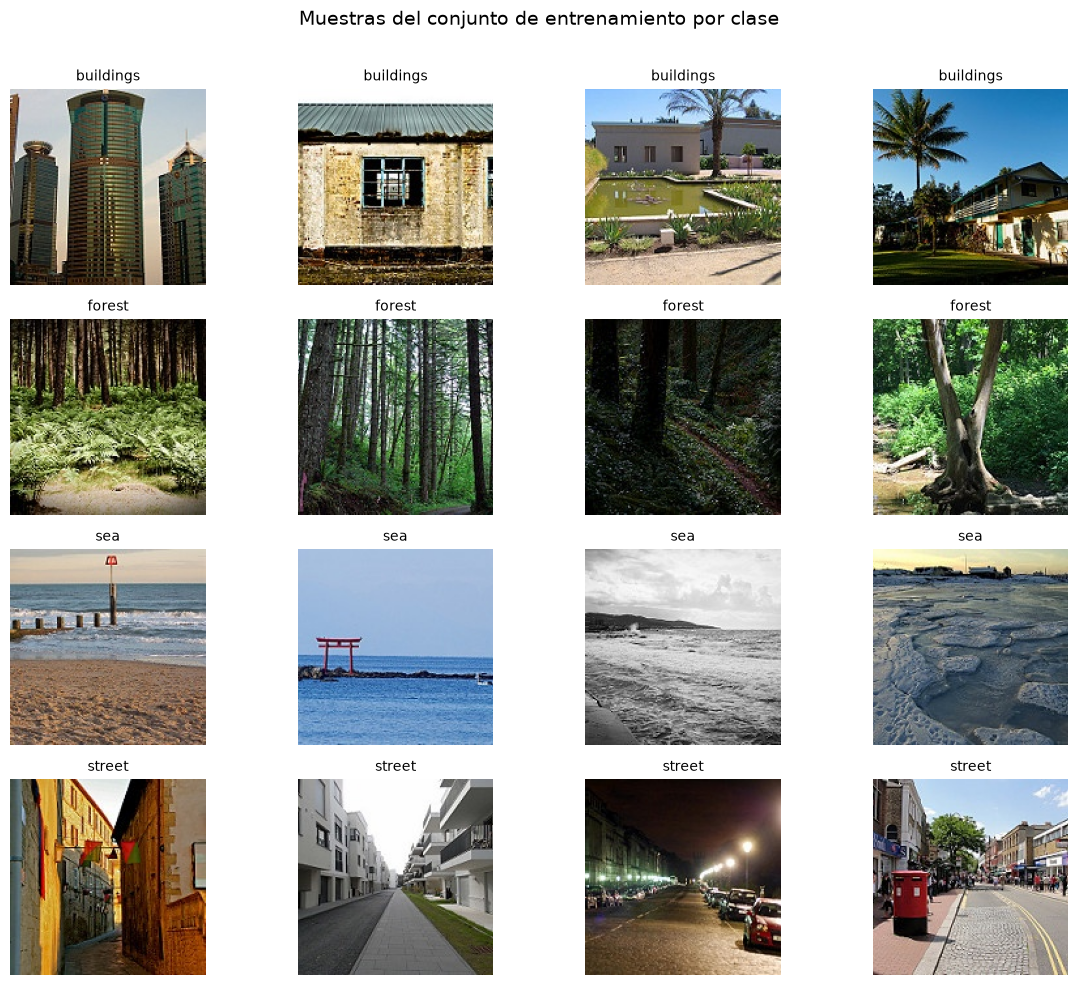

In [4]:
import random

MUESTRAS_POR_CLASE = 4
rng = random.Random(SEED)

fig, axes = plt.subplots(
    nrows=len(CLASES_SELECCIONADAS),
    ncols=MUESTRAS_POR_CLASE,
    figsize=(12, 10),
    squeeze=False
)

for row, class_name in enumerate(CLASES_SELECCIONADAS):
    class_dir = train_proc / class_name
    image_paths = sorted(
        path for path in class_dir.iterdir()
        if path.suffix.lower() in {".jpg", ".jpeg", ".png"}
    )

    if not image_paths:
        raise FileNotFoundError(f"No se encontraron imágenes para la clase: {class_name}")

    selected_paths = rng.sample(image_paths, k=min(MUESTRAS_POR_CLASE, len(image_paths)))

    for column, axis in enumerate(axes[row]):
        if column < len(selected_paths):
            image_path = selected_paths[column]
            axis.imshow(plt.imread(image_path))
            axis.set_title(class_name, fontsize=10)
        axis.axis("off")

fig.suptitle("Muestras del conjunto de entrenamiento por clase", fontsize=14)
fig.tight_layout(rect=(0, 0, 1, 0.97))
plt.show()

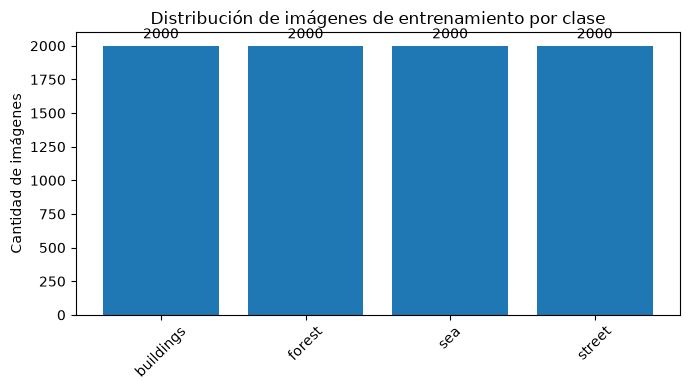

In [5]:
classes = CLASES_SELECCIONADAS
image_extensions = {".jpg", ".jpeg", ".png"}
counts = [
    sum(
        image_path.is_file() and image_path.suffix.lower() in image_extensions
        for image_path in (train_proc / class_name).iterdir()
    )
    for class_name in classes
]

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(classes, counts)
ax.bar_label(bars, padding=3)

plt.xticks(rotation=45)
plt.ylabel("Cantidad de imágenes")
plt.title("Distribución de imágenes de entrenamiento por clase")
plt.tight_layout()
plt.show()

El conjunto de datos se encuentra balanceado debido a las limitaciones en la cantidad de imagenes que fueron establecidas, y como las clases poseen la misma cantidad de imagenes. Esto nos permite ver que las diferencias de rendimiento observadas durante la auditoría no se deban, en principio, a un desbalance entre clases.

**2.4 Modelo Convolucional**

En esta estapa del proceso de entrenamiento de nuestro, estaremos viendo principalmente el tamaño de los datos a procesar, la cantidad de canales, cantidad de capas convolucionales, optimizadores y las diferentes metricas utilizadas.

**Capas convolucionales y el porque de ellas:**

En nuestras capas convolucionales comenzaria con nuestra entrada de datos **Input(shape=(TAMANO_IMAGEN[0], TAMANO_IMAGEN[1], 3))** que toma la misma cantidad de pixeles que se declararon anteriormente en las imagenes ocupando los tres canales de colores RGB (Rojo, Verde y Azul) 

Despues pasariamos a reescalar los valores de los pixeles **tf.keras.layers.Rescaling(1.0 / 255)** de las imagenes a un rango estandart de entre 0 y 1, esto ayuda a que el descenso de la gradiente sea mas suave y controlada cosa que ayuda a que llegue a una solucion mas optima y directa para el modelo 

Apartir de ellos seguiriamos con nuestras **capas convolucionales** estas son las encargadas de extraer la mayor cantidad de caracteristicas para nuestro modelo de aprendizaje pueda aprovechar los datos y asi mejorar el reconocimiento de las imagenes, todas extraen caracteristicas en porciones de **3x3** de las imagenes, la primera capa consta de **32 filtros** esta es la encargada de extraer las caracteristicas mas simples de la foto como bordes, lineas, esquinas, etc.

Las siquientes capas constans de **64 y 128 filtros** estas serian las encargadas de ya enfocarse en los detalles mas complejos de las imagenes como diferentes tipos de formas, siluetas, patrones especificos del objeto, etc.

El **MaxPooling2D()** lo ocupamos principalmente para extraer lo mejor de cada mapa de caracteristicas individual, y a medida que los filtros iban aumentando nos ayudaba justamente a extraer caracteristicas cada vez mas avanzadas

Nosotros decidimos mantener el uso de la función de **activación ReLU**, esto lo que hace es que no satura el desvanecimiento del gradiente con valores positivos, este nos da una garantia para un aprendizaje continuo en las capas mas profundas de nuestro modelo. Además, este al convertir los valores negativos a cero y mantener los valores positivos ayuda a una buena eficiencia computacional, reduce el tiempo de entrenamiento, genera una representación dispersa (sparsity) que hace al modelo más ligero, robusto y eficiente ante el sobreajuste.

**Optimizador adam**

Como optimizador estaremos utilizando **adam (Adaptive Moment Estimation)** este algoritmo es el encargado de actualizar los pesos a medida que va aprendiendo el modelo para de esta forma minimizar el error


**Loss "categorical_crossentropy"**

Es la función de pérdida que mide qué tan lejos están las predicciones del modelo de las etiquetas reales. Funciona castigando fuertemente al modelo si tiene mucha seguridad en una predicción incorrecta, lo que acelera el aprendizaje al inicio.



**Metricas ["recall", "precision", "f1_score"]**

**Precision (Precisión):** Mide cuántos de los elementos que el modelo clasificó como "Clase X" realmente pertenecían a esa clase. Es vital si el costo de un falso positivo es muy alto.
**Recall (Sensibilidad):** Mide la capacidad del modelo para encontrar todos los casos reales de una clase. Es crítico si no puedes permitirte falsos negativos (ej: omitir una enfermedad o un defecto de fabricación).
**F1-Score:** Es el promedio armónico entre Precision y Recall. Es la métrica definitiva para justificar que el modelo es estable y equilibrado, ideal si tus clases no tienen la misma cantidad de imágenes



In [6]:
model = Sequential([
    Input(shape=(TAMANO_IMAGEN[0], TAMANO_IMAGEN[1], 3)),
    tf.keras.layers.Rescaling(1.0 / 255),

    Conv2D(32, (3, 3), activation="relu", name="conv1"),
    MaxPooling2D(),

    Conv2D(64, (3, 3), activation="relu", name="conv2"),
    MaxPooling2D(),

    Conv2D(128, (3, 3), activation="relu", name="conv3"),
    MaxPooling2D(),

    Flatten(),
    Dense(128, activation="relu"),
    Dense(len(nombre_clases), activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy", "recall", "precision", "f1_score"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 62, 62, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 29, 29, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       589,952 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 683,716 (2.61 MB)

 Trainable params: 683,716 (2.61 MB)

 Non-trainable params: 0 (0.00 B)

**La cantidad de parámetros que nuestro modelo deberia aprender serian los siguientes:**

El modelo tiene que ajustar y optimizar un total de **683,716 parámetros** entrenables.
Podemos notar cómo la última capa densa (dense_5) tiene exactamente **516 parámetros**, lo cual confirma que el modelo esta adaptado la 4 clases que seleccionamos anteriormente 

**Datos guardados en las capas densas**

Los datos de las imágenes de entrada comienzan con 12,288 valores, al pasar por las capas convolucionales (**conv3**) y llegar a la capa de aplanado (**flatten_2**), el modelo extrae y estira las características en un vector de 4,608 datos por imagen, si lo multiplicamos por el batch size de nuestro modelo (32), la primera capa densa (**dense_4**) procesará una matriz de 147,456 datos en cada iteración ($32*4.608$) y apartir de aqui es donde se eleva el esfuerzo computacional debido a la transición de **flatten_2** a **dense_4**, este se lleva 589,952 parámetros, representando casi el 86% de todo el peso del modelo.

Epoch 1/10


/usr/local/python/3.14.2/lib/python3.14/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
W0000 00:00:1792355442.420029   25126 cpu_allocator_impl.cc:174] Allocation of 15745024 exceeds 10% of free system memory.


  1/200 ━━━━━━━━━━━━━━━━━━━━ 34:54 11s/step - accuracy: 0.1562 - f1_score: 0.0714 - loss: 1.3996 - precision: 0.0000e+00 - recall: 0.0000e+00

W0000 00:00:1792355442.706495   25126 cpu_allocator_impl.cc:174] Allocation of 14929920 exceeds 10% of free system memory.
W0000 00:00:1792355442.776298   25125 cpu_allocator_impl.cc:174] Allocation of 25189632 exceeds 10% of free system memory.
W0000 00:00:1792355442.821216   25126 cpu_allocator_impl.cc:174] Allocation of 15745024 exceeds 10% of free system memory.
W0000 00:00:1792355442.852085   25125 cpu_allocator_impl.cc:174] Allocation of 14530320 exceeds 10% of free system memory.


200/200 ━━━━━━━━━━━━━━━━━━━━ 44s 169ms/step - accuracy: 0.6830 - f1_score: 0.6841 - loss: 0.7707 - precision: 0.7873 - recall: 0.5691 - val_accuracy: 0.8175 - val_f1_score: 0.8127 - val_loss: 0.4991 - val_precision: 0.8607 - val_recall: 0.7606
Epoch 2/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 32s 160ms/step - accuracy: 0.8017 - f1_score: 0.8028 - loss: 0.5236 - precision: 0.8350 - recall: 0.7672 - val_accuracy: 0.8350 - val_f1_score: 0.8321 - val_loss: 0.4324 - val_precision: 0.8672 - val_recall: 0.8037
Epoch 3/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 40s 156ms/step - accuracy: 0.8288 - f1_score: 0.8299 - loss: 0.4551 - precision: 0.8580 - recall: 0.7980 - val_accuracy: 0.8531 - val_f1_score: 0.8485 - val_loss: 0.4031 - val_precision: 0.8804 - val_recall: 0.8331
Epoch 4/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 32s 162ms/step - accuracy: 0.8542 - f1_score: 0.8550 - loss: 0.3927 - precision: 0.8739 - recall: 0.8341 - val_accuracy: 0.8681 - val_f1_score: 0.8642 - val_loss: 0.3696 - val_precision: 0.8892 - val_recall

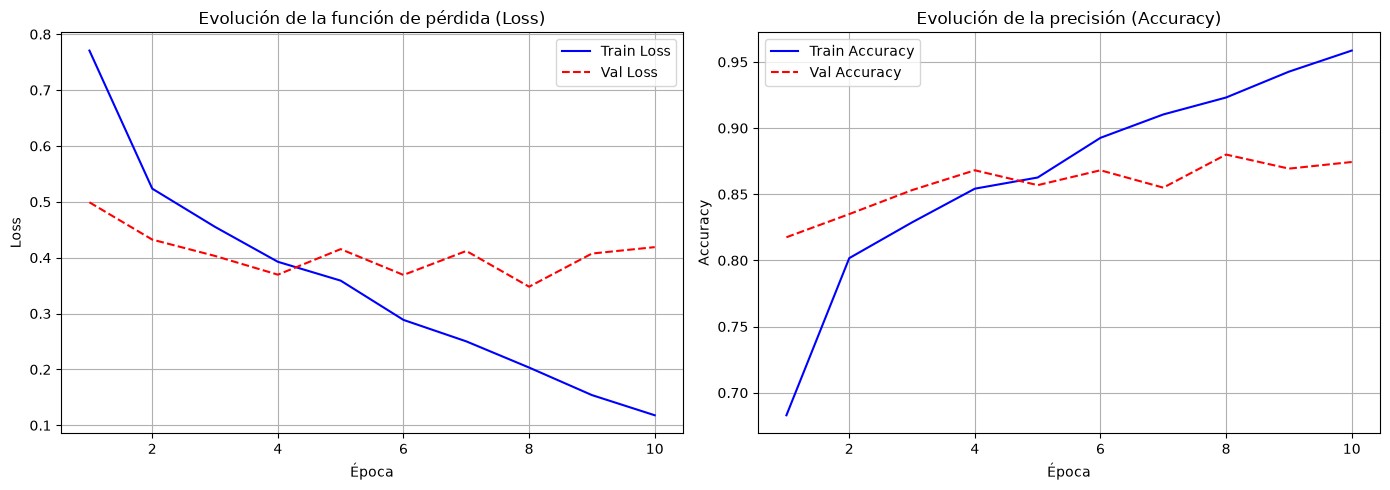

In [7]:
from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

epocas = 10
history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=epocas,
    callbacks=[early_stopping]
)

# Graficar las curvas para las épocas que realmente se ejecutaron
epocas_entrenadas = range(1, len(history.history["loss"]) + 1)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].plot(epocas_entrenadas, history.history["loss"], label="Train Loss", color="blue")
ax[0].plot(epocas_entrenadas, history.history["val_loss"], label="Val Loss", color="red", linestyle="--")
ax[0].set_title("Evolución de la función de pérdida (Loss)")
ax[0].set_xlabel("Época")
ax[0].set_ylabel("Loss")
ax[0].legend()
ax[0].grid(True)

ax[1].plot(epocas_entrenadas, history.history["accuracy"], label="Train Accuracy", color="blue")
ax[1].plot(epocas_entrenadas, history.history["val_accuracy"], label="Val Accuracy", color="red", linestyle="--")
ax[1].set_title("Evolución de la precisión (Accuracy)")
ax[1].set_xlabel("Época")
ax[1].set_ylabel("Accuracy")
ax[1].legend()
ax[1].grid(True)

fig.tight_layout()
plt.show()

In [1]:
# Graficar las métricas de Precision, Recall y F1-Score del historial del modelo
epocas_metricas = range(1, len(history.history["precision"]) + 1)
fig, ax = plt.subplots(1, 3, figsize=(21, 5))

ax[0].plot(epocas_metricas, history.history["precision"], label="Train Precision", color="blue")
ax[0].plot(epocas_metricas, history.history["val_precision"], label="Val Precision", color="red", linestyle="--")
ax[0].set_title("Evolución de la precisión (Precision)")
ax[0].set_xlabel("Época")
ax[0].set_ylabel("Precision")
ax[0].legend()
ax[0].grid(True)

ax[1].plot(epocas_metricas, history.history["recall"], label="Train Recall", color="blue")
ax[1].plot(epocas_metricas, history.history["val_recall"], label="Val Recall", color="red", linestyle="--")
ax[1].set_title("Evolución del Recall")
ax[1].set_xlabel("Época")
ax[1].set_ylabel("Recall")
ax[1].legend()
ax[1].grid(True)

ax[2].plot(epocas_metricas, history.history["f1_score"], label="Train F1-Score", color="blue")
ax[2].plot(epocas_metricas, history.history["val_f1_score"], label="Val F1-Score", color="red", linestyle="--")
ax[2].set_title("Evolución del F1-Score")
ax[2].set_xlabel("Época")
ax[2].set_ylabel("F1-Score")
ax[2].legend()
ax[2].grid(True)

fig.tight_layout()
plt.show()

NameError: name 'history' is not defined